# Vignette OCR — Tutorial dari Awal (lanjutan dari EDA-mu)

**Peta jalan:** `Setup` → `EDA lanjutan` → `Keputusan` → `Label teks` → `Detektor` → `Crop + orientasi` → `Pengenal teks` → `Submission`

Prinsip utama notebook ini: **setiap langkah muncul dari sebuah temuan data**, bukan dari kebiasaan.
Bagian yang butuh gambar akan dilewati otomatis jika folder gambar belum ada.

## 0. Setup yang rapi
Notebook-mu sebelumnya punya beberapa masalah kecil: `test_df` tidak terdefinisi (yang ada `df_test`), `json`/`Counter`/`patches` belum di-import, dan nama file anotasi tidak cocok. Sel ini merapikan semuanya.

Catatan penting: `id` di **train.csv tidak memakai ekstensi** (`WIN_..._jpg.rf.<hash>`), sedangkan `id` di **test.csv memakai `.jpg`**. Di submission, kolom `id` harus persis seperti `sample_submission.csv`.

In [1]:
import json, random, shutil
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)   # hasil acak bisa diulang

DATA_DIR  = Path(".")               # folder kerja (sesuaikan)
TRAIN_DIR = DATA_DIR / "train"      # gambar train
TEST_DIR  = DATA_DIR / "test"       # gambar test

# Pilih GPU (CUDA) bila ada, jika tidak jatuh ke CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
YOLO_DEVICE = 0 if torch.cuda.is_available() else "cpu"   # Ultralytics memakai indeks GPU (0) atau "cpu"
print(f"🔧 Using device: {DEVICE}")
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
    print(f"   GPU: {torch.cuda.get_device_name(0)}")

# Nama file anotasi berbeda-beda antar ekspor Roboflow, jadi cari yang ada.
candidates = [TRAIN_DIR / "_annotations.coco.json",
              DATA_DIR / "_annotations.coco.json",
              DATA_DIR / "_annotations_coco.json"]
coco_path = next(p for p in candidates if p.exists())

# Konstanta untuk detektor (tahap 5). COCO_PATH memakai path yang BENAR-BENAR ditemukan di atas.
COCO_PATH = coco_path
IMG_SRC   = TRAIN_DIR                 # folder gambar training
YOLO_DIR  = DATA_DIR / "yolo_data"    # keluaran dataset format YOLO (bukan 'OUT', agar tidak tertimpa sel lain)
BLOCK     = 25                        # ukuran blok frame berurutan
VAL_EVERY = 5                         # setiap blok ke-5 menjadi validasi (~20%)
with open(coco_path, encoding="utf-8") as f:
    coco = json.load(f)

df_train  = pd.read_csv(DATA_DIR / "train.csv")
df_test   = pd.read_csv(DATA_DIR / "test.csv")
df_sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

# Kategori id 0 ('Images') hanyalah placeholder Roboflow -> abaikan.
id2cat = {c["id"]: c["name"] for c in coco["categories"] if c["supercategory"] != "none"}
img_by_id = {im["id"]: im for im in coco["images"]}

# Kelompokkan anotasi per gambar sekali saja (lebih cepat daripada loop berulang).
anns_by_img = defaultdict(list)
for a in coco["annotations"]:
    anns_by_img[a["image_id"]].append(a)

# Sanity check: id di train.csv harus sama dengan nama file di anotasi (tanpa ekstensi).
stems = {Path(im["file_name"]).stem for im in coco["images"]}
assert set(df_train["id"]) == stems, "id train.csv tidak cocok dengan anotasi COCO"
assert set(df_test["id"]) == set(df_sample["id"]), "id test.csv tidak cocok dengan sample_submission"
print(f"train: {len(df_train)} | test: {len(df_test)} | kelas: {id2cat}")

🔧 Using device: cuda
   GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
train: 750 | test: 674 | kelas: {1: 'entete', 2: 'vin'}


## 1. Apa yang sudah dikatakan EDA-mu, dan apa artinya

| Temuan EDA | Artinya untuk langkah berikutnya |
|---|---|
| 750 gambar, 1509 anotasi, `entete` 754 dan `vin` 755 | Hampir tepat satu pasang per gambar → detektor 2 kelas yang sederhana. Selisihnya (9 gambar punya 3 anotasi) harus diperiksa. |
| `vin` ±38% luas gambar, `entete` ±7%, ukuran sangat seragam (std lebar/tinggi `vin` hanya ±8 px) | Objek besar dan konsisten → **deteksi adalah bagian mudah**. Jangan habiskan waktu menyetel detektor; waktu terbaik ada di pengenal teks. |
| `entete` hanya ±65×182 piksel pada gambar 416 | Teks di dalamnya **sangat kecil**. Resolusi crop akan menentukan akurasi OCR → kita perlu cek resolusi asli (bagian 2.3). |
| Tidak ada `vin` yang menyentuh tepi gambar | Stiker selalu utuh di dalam bingkai: tidak perlu menangani objek terpotong. |

EDA-mu **belum menjawab** empat hal yang menentukan keberhasilan. Itulah isi bagian 2.

## 2. EDA lanjutan

### 2.1 Integritas anotasi: 9 gambar yang tidak normal

(entete, vin) -> jumlah gambar: {(1, 1): 741, (1, 2): 5, (2, 1): 4}
9 gambar anomali:
  WIN_20200702_16_19_13_Pro_jpg.rf.a9c5eeed0c27af9cf0f3e5aac9fe0857.jpg
  WIN_20200702_18_20_31_Pro_jpg.rf.dac2c539c0d35ab5fa69228ef21dd1d7.jpg
  WIN_20200702_18_56_36_Pro_jpg.rf.f18702e73540baacbe588aee46a86082.jpg
  WIN_20200702_18_38_27_Pro_jpg.rf.c1ade92eb1f93d911c759fd685cd7204.jpg
  WIN_20200702_15_46_14_Pro_jpg.rf.5588275fa80b86a45120c6565ec0cbe2.jpg
  WIN_20200702_16_31_11_Pro_jpg.rf.b76a4cc6a3b5f7d6cde0c1916d780c09.jpg
  WIN_20200702_16_23_53_Pro_jpg.rf.0a5671b26230b74addafc229e6046729.jpg
  WIN_20200702_19_17_12_Pro_jpg.rf.d5784dba2a94fac534a9bd8fc23f0b00.jpg
  WIN_20200702_14_56_19_Pro_jpg.rf.4d2e4084345c1bd1741330f9dad8803f.jpg


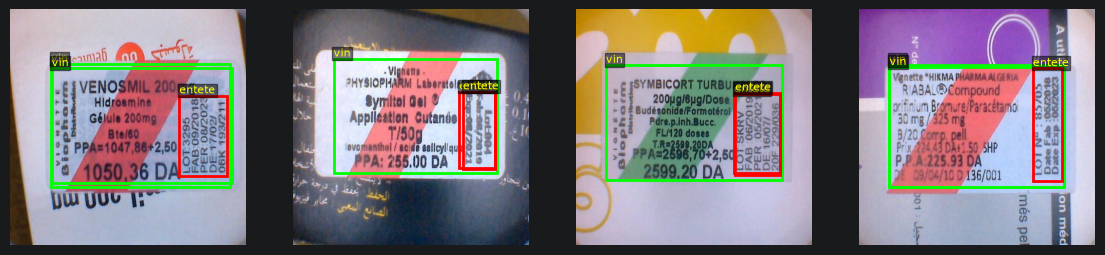

In [2]:
# Pola per gambar: (jumlah entete, jumlah vin). Normalnya (1, 1).
pola = Counter()
for im_id, lst in anns_by_img.items():
    c = Counter(id2cat[a["category_id"]] for a in lst)
    pola[(c["entete"], c["vin"])] += 1
print("(entete, vin) -> jumlah gambar:", dict(pola))

anomali = [img_by_id[i]["file_name"] for i, lst in anns_by_img.items() if len(lst) != 2]
print(f"{len(anomali)} gambar anomali:", *anomali, sep="\n  ")

def draw(ax, file_name, folder=TRAIN_DIR):
    """Gambar foto + kotak anotasinya."""
    im_id = next(i for i, im in img_by_id.items() if im["file_name"] == file_name)
    ax.imshow(Image.open(folder / file_name).convert("RGB"))
    for a in anns_by_img[im_id]:
        x, y, w, h = a["bbox"]
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, lw=2,
                     ec="lime" if id2cat[a["category_id"]] == "vin" else "red"))
        ax.text(x, max(y - 4, 0), id2cat[a["category_id"]], color="yellow", fontsize=8,
                bbox=dict(facecolor="black", alpha=.5, pad=1))
    ax.axis("off")

if TRAIN_DIR.exists() and anomali:
    fig, axs = plt.subplots(1, min(len(anomali), 4), figsize=(14, 4))
    for ax, fn in zip(np.atleast_1d(axs), anomali[:4]):
        draw(ax, fn)
    plt.show()

**Yang kamu lakukan dengan hasilnya:** lihat 9 gambar itu. Kemungkinannya: kotak ganda yang salah (hapus salah satu), atau memang ada dua stiker (pertahankan). Putuskan dan catat. Anotasi yang salah akan mengajari detektor hal yang salah.

### 2.2 Orientasi: sisi `entete` terhadap `vin`
Posisi `x` `entete` bersifat **bimodal** (histogramnya dua puncak). Kalau sisi kiri/kanan itu mencerminkan putaran stiker, kita butuh langkah luruskan orientasi sebelum OCR.

{'kiri': 382, 'kanan': 359}
pergantian sisi: 342 dari 740 pasang frame berurutan


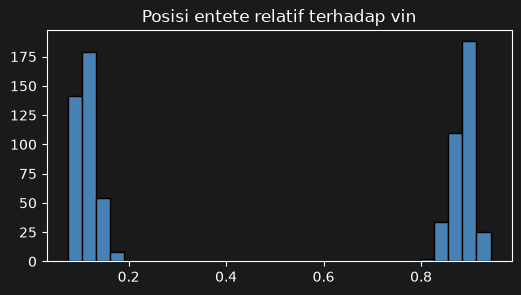

In [3]:
rows = []
for im_id, lst in anns_by_img.items():
    ent = [a["bbox"] for a in lst if id2cat[a["category_id"]] == "entete"]
    vin = [a["bbox"] for a in lst if id2cat[a["category_id"]] == "vin"]
    if len(ent) == 1 and len(vin) == 1:                  # hanya gambar normal
        e, v = ent[0], vin[0]
        rows.append(dict(name=img_by_id[im_id]["extra"]["name"],
                         # posisi tengah entete relatif terhadap lebar vin: 0 = tepi kiri, 1 = tepi kanan
                         rel_x=((e[0] + e[2] / 2) - v[0]) / v[2]))
ori = pd.DataFrame(rows).sort_values("name").reset_index(drop=True)
ori["sisi"] = np.where(ori.rel_x < 0.5, "kiri", "kanan")
print(ori.sisi.value_counts().to_dict())

# Seberapa sering sisi berganti pada urutan waktu? Jika sekitar 50% pasangan berurutan
# berganti (setara lempar koin), orientasinya acak, bukan kebiasaan satu sesi pengambilan.
ganti = (ori.sisi != ori.sisi.shift()).sum() - 1
print(f"pergantian sisi: {ganti} dari {len(ori) - 1} pasang frame berurutan")

plt.figure(figsize=(6, 3)); plt.hist(ori.rel_x, bins=30, color="steelblue", edgecolor="k")
plt.title("Posisi entete relatif terhadap vin"); plt.show()

**Cara membaca:** jika pembagiannya ±50/50 dan sekitar separuh pasangan frame berurutan berganti sisi (setara lempar koin), stiker diletakkan dengan orientasi acak (dugaan: terputar 180°). Karena sisi `entete` sudah memberi tahu orientasinya, **kita tidak perlu melatih model klasifikasi orientasi**; cukup rotasi 180° bila `entete` ada di sisi "salah". Sisi mana yang benar harus kamu tentukan dengan melihat gambar (bagian 2.4).

### 2.3 Resolusi dan rasio aspek: train vs test  ⟵ paling penting
Train berukuran 416×416 karena Roboflow men-*resize*. Nama file asli `WIN_...` (tangkapan webcam) biasanya 16:9. Jika Roboflow memakai mode *stretch*, gambar train **terkompresi horizontal** dan huruf menjadi sempit. Test mungkin masih ukuran asli. Kalau tidak dicek, model dilatih pada satu "dunia" dan diuji pada dunia lain.

In [4]:
def ukuran(folder, names, n=None):
    """Baca ukuran gambar tanpa memuat pikselnya (cepat)."""
    names = names[:n] if n else names
    return [Image.open(folder / nm).size for nm in names if (folder / nm).exists()]

train_sizes = ukuran(TRAIN_DIR, [im["file_name"] for im in coco["images"]])
test_sizes  = ukuran(TEST_DIR, df_test["id"].tolist())

for nama, s in [("train", train_sizes), ("test", test_sizes)]:
    if not s:
        print(f"{nama}: folder gambar tidak ditemukan -> lewati"); continue
    c = Counter(s).most_common(5)
    asp = np.array([w / h for w, h in s])
    print(f"{nama}: {len(s)} gambar | ukuran terbanyak: {c} | rasio w/h min-rata2-maks: "
          f"{asp.min():.2f}-{asp.mean():.2f}-{asp.max():.2f}")

train: 750 gambar | ukuran terbanyak: [((416, 416), 750)] | rasio w/h min-rata2-maks: 1.00-1.00-1.00
test: 674 gambar | ukuran terbanyak: [((480, 480), 458), ((540, 540), 8), ((576, 576), 8), ((546, 546), 8), ((568, 568), 7)] | rasio w/h min-rata2-maks: 1.00-1.00-1.00


**Putusan dari hasilnya:**
- Test juga 416×416 persegi → domain sama, lanjut.
- Test berukuran besar/16:9 → **jangan** langsung memberi ke detektor. Resize dengan cara yang sama seperti train (stretch ke 416×416) untuk mendeteksi, lalu pakai koordinat *ternormalisasi* untuk memotong dari gambar **resolusi penuh**. Crop dari gambar penuh jauh lebih tajam untuk OCR.

### 2.4 Lihat crop-nya (jangan lewati)

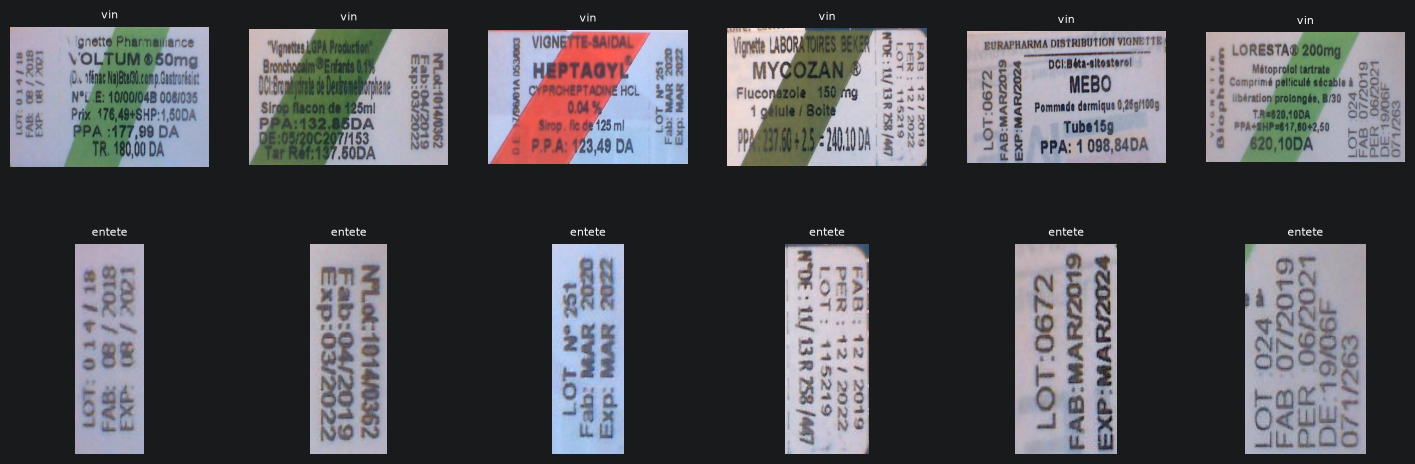

In [5]:
def crop_kelas(file_name, nama_kelas, pad=4, folder=TRAIN_DIR):
    """Potong bounding box suatu kelas dari gambar train (pad = margin piksel)."""
    im_id = next(i for i, im in img_by_id.items() if im["file_name"] == file_name)
    img = Image.open(folder / file_name).convert("RGB")
    for a in anns_by_img[im_id]:
        if id2cat[a["category_id"]] == nama_kelas:
            x, y, w, h = a["bbox"]
            return img.crop((max(x - pad, 0), max(y - pad, 0),
                             min(x + w + pad, img.width), min(y + h + pad, img.height)))

if TRAIN_DIR.exists():
    sampel = random.sample([im["file_name"] for im in coco["images"]], 6)
    fig, axs = plt.subplots(2, 6, figsize=(18, 6))
    for j, fn in enumerate(sampel):
        axs[0, j].imshow(crop_kelas(fn, "vin"));    axs[0, j].set_title("vin", fontsize=8)
        axs[1, j].imshow(crop_kelas(fn, "entete")); axs[1, j].set_title("entete", fontsize=8)
        axs[0, j].axis("off"); axs[1, j].axis("off")
    plt.show()

**Pertanyaan yang harus kamu jawab setelah melihat gambar** (tulis jawabannya di sel di bawah):
1. Di bagian mana tulisan `N°LOT / FAB / EXP` berada: di `entete`, di `vin`, atau di tempat lain?
2. Apakah teks di crop tampak miring, terbalik, atau terputar 90°?
3. Seberapa terbaca teksnya dengan mata telanjang pada resolusi ini?

In [6]:
# Isi setelah melihat gambar:
TARGET_CLASS   = "entete"   # kelas yang memuat teks (ganti jika ternyata "vin")
UPRIGHT_SIDE   = "kiri"     # sisi entete pada stiker yang tegak (kiri/kanan)
ROTATE_TO_READ = 0          # putaran searah jarum jam (0/90/180/270) agar teks horizontal

## 3. Keputusan setelah EDA

| Pertanyaan | Dijawab oleh | Konsekuensi |
|---|---|---|
| Apakah ada label teks? | Tab *Data* Kaggle | Jika tidak ada → langkah 4 wajib |
| Metrik evaluasi dan format teks? | Tab *Evaluation* | Menentukan post-processing dan cara validasi |
| Domain train = test? | Sel 2.3 | Menentukan strategi resize dan crop |
| Teks ada di kelas mana, putaran berapa? | Sel 2.4 | Mengisi `TARGET_CLASS`, `UPRIGHT_SIDE`, `ROTATE_TO_READ` |

## 4. Menyiapkan label teks
Train hanya punya kotak, **tanpa teks**. Tanpa teks, pengenal teks tidak bisa dilatih atau divalidasi. Sel ini mengekspor 200 crop acak beserta `labels.csv` kosong untuk kamu isi manual (ketik persis seperti format yang diminta Kaggle). 200 crop adalah investasi yang membuat setiap eksperimen berikutnya terukur.

In [7]:
N_LABEL = 200
LABEL_DIR = DATA_DIR / "label_work"
(LABEL_DIR / "crops").mkdir(parents=True, exist_ok=True)

if TRAIN_DIR.exists():
    pilih = random.sample([im["file_name"] for im in coco["images"]], N_LABEL)
    rows = []
    for fn in pilih:
        crop = crop_kelas(fn, TARGET_CLASS)
        if crop is None:                       # gambar tanpa kelas target dilewati
            continue
        stem = Path(fn).stem
        crop.save(LABEL_DIR / "crops" / f"{stem}.png")
        rows.append({"id": stem, "text": ""})  # kolom text diisi manual
    pd.DataFrame(rows).to_csv(LABEL_DIR / "labels.csv", index=False)
    print(f"{len(rows)} crop diekspor ke {LABEL_DIR}. Isi kolom 'text' di labels.csv.")

200 crop diekspor ke label_work. Isi kolom 'text' di labels.csv.


## 5. Detektor
Jalankan skrip tahap 1 (`stage1_prepare_and_train_detector.py`). Ia mengonversi COCO → YOLO, membagi train/val per blok waktu, lalu melatih YOLOv8s. Karena deteksi mudah (lihat bagian 1), cukup periksa bahwa mAP di val sangat tinggi, lalu lanjut.

In [8]:
def build_dataset():
    with open(COCO_PATH, encoding="utf-8") as f:
        coco = json.load(f)

    # Roboflow menambahkan kategori 'Images' (id 0) sebagai supercategory kosong.
    # Kelas nyata hanya id 1 (entete) dan id 2 (vin) -> petakan ke 0 dan 1 untuk YOLO.
    real_cats = sorted(
        (c for c in coco["categories"] if c["supercategory"] != "none"),
        key=lambda c: c["id"],
    )
    cat2yolo = {c["id"]: i for i, c in enumerate(real_cats)}
    names = [c["name"] for c in real_cats]

    # Kelompokkan anotasi per gambar agar pencarian O(1), bukan loop berulang.
    anns = defaultdict(list)
    for a in coco["annotations"]:
        anns[a["image_id"]].append(a)

    # Urutkan berdasarkan nama asli (mengandung timestamp WIN_YYYYMMDD_HH_MM_SS).
    images = sorted(coco["images"], key=lambda im: im["extra"]["name"])

    for split in ("train", "val"):
        (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
        (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

    n_missing, counts = 0, {"train": 0, "val": 0}
    for idx, im in enumerate(images):
        split = "val" if (idx // BLOCK) % VAL_EVERY == VAL_EVERY - 1 else "train"
        W, H = im["width"], im["height"]
        stem = Path(im["file_name"]).stem

        lines = []
        for a in anns[im["id"]]:
            x, y, w, h = a["bbox"]                      # COCO: pojok kiri-atas + lebar/tinggi (piksel)
            cx, cy = (x + w / 2) / W, (y + h / 2) / H   # YOLO: titik tengah, ternormalisasi 0-1
            lines.append(f"{cat2yolo[a['category_id']]} {cx:.6f} {cy:.6f} {w / W:.6f} {h / H:.6f}")
        (YOLO_DIR / "labels" / split / f"{stem}.txt").write_text("\n".join(lines))

        src = IMG_SRC / im["file_name"]
        if src.exists():
            shutil.copy(src, YOLO_DIR / "images" / split / im["file_name"])
        else:
            n_missing += 1
        counts[split] += 1

    yaml_text = (
        f"path: {YOLO_DIR.resolve()}\n"
        "train: images/train\n"
        "val: images/val\n"
        f"names: {dict(enumerate(names))}\n"
    )
    (YOLO_DIR / "data.yaml").write_text(yaml_text)
    print(f"split: {counts} | gambar tidak ditemukan: {n_missing}")
    return YOLO_DIR / "data.yaml"

In [9]:
def train(data_yaml):
    import torch
    from ultralytics import YOLO

    device = 0 if torch.cuda.is_available() else "cpu"   # 0 = GPU CUDA pertama
    print("device training:", device)

    model = YOLO("yolov8s.pt")      # model kecil: muat di GPU 6 GB dan cepat dilatih
    model.train(
        data=str(data_yaml),
        imgsz=416,                   # sama dengan resolusi data training
        epochs=60,
        batch=16,
        seed=42,
        device=device,               # paksa pakai GPU bila tersedia
        fliplr=0.0,                  # JANGAN flip horizontal: teks akan menjadi cermin
        degrees=5,                   # rotasi kecil saja
        project="runs_vignette",
        name="detector_v1",
    )

In [10]:
yaml_path = build_dataset()      # buat yolo_data/ + data.yaml, lalu cetak jumlah train/val
# train(yaml_path)               # aktifkan setelah isi yolo_data/labels/ diperiksa

split: {'train': 600, 'val': 150} | gambar tidak ditemukan: 0


## 6. Detect → crop → luruskan  *(kerangka, belum diuji dengan gambar)*
Rancangannya mengikuti temuan EDA:
1. Resize gambar ke 416×416 **dengan stretch** (sama seperti train) hanya untuk detektor.
2. Ambil kotak `vin` dan `entete` dengan confidence tertinggi (menangani anomali ganda).
3. Pakai koordinat **ternormalisasi** untuk memotong dari gambar resolusi penuh.
4. Jika sisi `entete` ≠ `UPRIGHT_SIDE`, putar 180°; lalu putar `ROTATE_TO_READ` agar teks horizontal.

In [11]:
def detect_and_crop(model, path, pad=0.02):
    """Kembalikan crop teks yang sudah diluruskan (PIL.Image) atau None bila gagal."""
    img = Image.open(path).convert("RGB")
    det_in = img.resize((416, 416))                    # stretch -> sama dengan data train
    r = model.predict(det_in, imgsz=416, device=YOLO_DEVICE, verbose=False)[0]   # deteksi di GPU
    best = {}                                          # kelas -> (conf, kotak ternormalisasi)
    for box, cls, conf in zip(r.boxes.xyxyn.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist()):
        name = r.names[int(cls)]
        if name not in best or conf > best[name][0]:
            best[name] = (conf, box)
    if "vin" not in best or TARGET_CLASS not in best:
        return None                                    # deteksi gagal -> tangani di pemanggil

    W, H = img.size
    x1, y1, x2, y2 = best[TARGET_CLASS][1]
    crop = img.crop((max((x1 - pad) * W, 0), max((y1 - pad) * H, 0),
                     min((x2 + pad) * W, W), min((y2 + pad) * H, H)))

    # Orientasi: bandingkan posisi entete terhadap vin.
    vx1, _, vx2, _ = best["vin"][1]
    ex_center = (best["entete"][1][0] + best["entete"][1][2]) / 2 if "entete" in best else None
    if ex_center is not None:
        sisi = "kiri" if (ex_center - vx1) / (vx2 - vx1) < 0.5 else "kanan"
        if sisi != UPRIGHT_SIDE:
            crop = crop.rotate(180)
    if ROTATE_TO_READ:
        crop = crop.rotate(-ROTATE_TO_READ, expand=True)   # PIL memutar berlawanan arah jarum jam
    return crop

## 7. Pengenal teks
Pakai `stage3_recognizer_resnet_transformer_ctc.py` (ResNet18 stride (2,1) → collapse tinggi → Transformer Encoder → CTC). Urutan kerja:
1. Bangun `Vocab` dari **teks di `labels.csv`**.
2. Latih pada campuran crop berlabel dan crop sintetis; validasi **hanya** pada crop nyata.
3. Tentukan cara menangani tiga baris (lihat catatan di bawah) sebelum melatih.

> **Catatan tiga baris:** CTC membaca satu urutan kiri→kanan, sedangkan tiga baris yang ditumpuk saling tumpang tindih secara horizontal. Pilih salah satu: (a) potong tiap baris lalu sambung menyamping, (b) latih pengenal per baris, atau (c) ganti CTC dengan dekoder attention. Putuskan setelah melihat crop nyata.

In [12]:
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

In [13]:
class Vocab:
    """Indeks 0 dicadangkan untuk token 'blank' milik CTC."""

    def __init__(self, texts):
        self.chars = sorted(set("".join(texts)))
        self.c2i = {c: i + 1 for i, c in enumerate(self.chars)}
        self.size = len(self.chars) + 1

    def encode(self, s):
        return [self.c2i[c] for c in s]

    def greedy_decode(self, logits):
        """logits: (B, T, C) -> list[str]. Ambil argmax, gabungkan ulangan, buang blank."""
        out = []
        for seq in logits.argmax(-1).tolist():
            prev, chars = 0, []
            for k in seq:
                if k != prev and k != 0:
                    chars.append(self.chars[k - 1])
                prev = k
            out.append("".join(chars))
        return out


In [14]:
class PositionalEncoding(nn.Module):
    """Sinusoidal: memberi tahu Transformer posisi tiap kolom (Transformer tidak peka urutan)."""

    def __init__(self, d_model, max_len=1024):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):                       # x: (B, T, d_model)
        return x + self.pe[:, : x.size(1)]


class Recognizer(nn.Module):
    def __init__(self, num_classes, d_model=256, nhead=8, num_layers=3, pretrained=True):
        super().__init__()
        r = torchvision.models.resnet18(weights="IMAGENET1K_V1" if pretrained else None)
        # "Modified strides (2,1)": layer2-4 hanya mengecilkan TINGGI, lebar dipertahankan
        # agar karakter yang rapat tetap punya langkah waktu sendiri-sendiri.
        for layer in (r.layer2, r.layer3, r.layer4):
            layer[0].conv1.stride = (2, 1)
            layer[0].downsample[0].stride = (2, 1)
        self.cnn = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool,
                                 r.layer1, r.layer2, r.layer3, r.layer4)
        self.proj = nn.Linear(512, d_model)
        self.pos = PositionalEncoding(d_model)
        layer = nn.TransformerEncoderLayer(d_model, nhead, 4 * d_model, 0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers)
        self.head = nn.Linear(d_model, num_classes)

    def forward(self, x):                       # x: (B, 3, H, W)
        f = self.cnn(x)                         # (B, 512, H', W')
        f = f.mean(dim=2).permute(0, 2, 1)      # collapse H -> (B, W', 512)
        f = self.encoder(self.pos(self.proj(f)))
        return self.head(f)                     # logits (B, T, C)



In [15]:
def ctc_step(model, images, targets, vocab, criterion):
    """Satu langkah loss CTC. targets: list[str]."""
    device = next(model.parameters()).device                 # ikuti lokasi model (cuda/cpu)
    images = images.to(device, non_blocking=True)            # pindahkan batch gambar ke GPU
    logits = model(images)                                   # (B, T, C)
    log_probs = F.log_softmax(logits, -1).permute(1, 0, 2)   # CTC minta (T, B, C)
    enc = [torch.tensor(vocab.encode(t)) for t in targets]
    tgt = torch.cat(enc)                                     # semua label disambung jadi 1 vektor (tetap di CPU)
    in_len = torch.full((len(targets),), log_probs.size(0), dtype=torch.long)
    tgt_len = torch.tensor([len(e) for e in enc], dtype=torch.long)
    return criterion(log_probs, tgt, in_len, tgt_len), logits

In [16]:
def smoke_test():
    """Pastikan bentuk benar dan model bisa menghafal 4 gambar teks sintetis (di GPU bila ada)."""
    from PIL import ImageDraw

    print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
    texts = ["EXP : 06 / 2022", "FAB : 07 / 2019", "N°LOT : 9275", "EXP : 11 / 2024"]
    vocab = Vocab(texts)

    def render(t):
        im = Image.new("RGB", (256, 64), "white")
        ImageDraw.Draw(im).text((8, 24), t, fill="black")
        a = torch.from_numpy(np.array(im)).permute(2, 0, 1).float() / 255
        return (a - 0.5) / 0.5

    x = torch.stack([render(t) for t in texts]).to(DEVICE)             # data ke GPU
    model = Recognizer(vocab.size, pretrained=False).to(DEVICE)        # parameter model ke GPU
    print("logits:", tuple(model(x).shape), "(B, T, C)")

    crit = nn.CTCLoss(blank=0, zero_infinity=True)
    opt = torch.optim.AdamW(model.parameters(), 1e-3)
    for step in range(301):
        loss, logits = ctc_step(model, x, texts, vocab, crit)
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 100 == 0:
            print(f"step {step:3d} loss {loss.item():.3f}")
    model.eval()
    with torch.no_grad():
        print(vocab.greedy_decode(model(x)))

smoke_test()

device: cuda NVIDIA GeForce RTX 3050 6GB Laptop GPU
logits: (4, 64, 23) (B, T, C)
step   0 loss 9.820
step 100 loss 1.069
step 200 loss 1.284
step 300 loss 0.126
['EXP : 06 / 24', 'FAB : 07 / 2019', 'N°LOT : 975', 'EXP : 11 / 24']


## 8. Submission
Pastikan `id` dan urutannya sama dengan `sample_submission.csv`, kolom `text` tidak kosong (isi cadangan bila deteksi gagal), dan simpan tanpa indeks.

In [17]:
def tulis_submission(pred: dict, path="submission.csv", fallback="UNKNOWN"):
    """pred: {id_test: teks}. Bila id tidak ada atau teks kosong, pakai fallback."""
    out = df_sample[["id"]].copy()                      # urutan & id persis seperti sample
    out["text"] = [pred.get(i) or fallback for i in out["id"]]
    assert len(out) == len(df_sample) and out["id"].is_unique
    out.to_csv(path, index=False)
    print(f"tersimpan: {path} | terisi fallback: {(out.text == fallback).sum()} baris")
    return out